# Complexity-08c — Machines de Gödel : l'auto-amélioration prouvée, en jouet honnête — CSharp

*Strand Schmidhuber, carnet d'origine ICT (anciennement ICT-49).*

**Navigation** : [<< Complexity-08b — Combinateurs SKI et tag de Post](Complexity-08b-CombinateursSKI-TagDePost-Python.ipynb) | [Index de la série](README.md) | [Complexity-08d — Indépendance prouvée >>](Complexity-08d-IndependanceProuvee-BusyBeaver-Covering-Python.ipynb) | Strand Schmidhuber (ICT) : [ICT-17b — Grokking et compression-progress](../../IIT/ICT-Series/ICT-17-EpsilonMachine/ICT-17b-Grokking-CompressionProgress-Python.ipynb) · [ICT-MUH — Fibre Tegmark](../../IIT/ICT-Series/ICT-MUH-FibreTegmark-Python.ipynb) | [jumeau Python](Complexity-08c-MachinesDeGoedel-Python.ipynb)

**Idée centrale.** Une machine de Gödel (Schmidhuber 2003-2006) est un programme qui réécrit son propre code quand — et seulement quand — il a **prouvé**, dans un système formel axiomatisant son propre matériel, son environnement et sa fonction d'utilité, que la réécriture augmente l'utilité future. Le théorème cible (eq. 2 du papier) est `u[s(t1) | switch] > u[s(t1) | keep]` ; sa preuve déclenche `check()`, qui pose le switchbit et applique le switchprog. Ce carnet construit un **jouet exécutable** de chaque mécanisme, avec l'organe `GoedelMachine` (port .NET de [`ict.goedel_machine`](../../IIT/ICT-Series/ict/goedel_machine.py), réimplémenté dans ce carnet) : théorème cible, chercheur bias-optimal BIOPS, garde FAQ 7 contre le réécrivain d'utilité, optimalité globale du switch apparemment glouton (Th. 4.1), gel-réutilisation OOPS.

**Résultat (honnête, falsifiable).** Tout ce qui suit est **mesuré**, pas raconté : le chercheur prouve le switch du levier et la marge prouvée (14) égale exactement le gain réalisé (14) ; le réécrivain d'utilité ne passe **jamais** — 0 feu sur les 9 331 techniques de l'espace borné, énumération exhaustive — et ce zéro a **deux causes distinctes**, mesurées séparément : la garde par fermeture (`SETSW`/`CHECK` n'acceptent que des `u` prouvés) *et* la borne de longueur (`L_MAX = 5`), qui exclut de l'espace la combinaison de `BOGUS` avec le squelette gagnant (section 8, item 3), sans exclure les techniques contenant `BOGUS` à elles seules ; l'écart de phases de découverte suit exactement le coût de codage (Th. 5.1 : Δc = 8 bits → 8 phases d'écart) ; le switch glouton est l'argmax de tous les candidats futurs et aucun second switch n'est prouvable ensuite (Th. 4.1) ; la technique gelée transfère sur une variante du monde à plusieurs ordres de grandeur de travail en moins (OOPS). Le carnet documente aussi **où le jouet triche** (section 8) : complétude du système formel sur son espace fini, auto-référence simplifiée, saturation straight-line du budget, et l'instruction du papier remplacée par une instruction inventée.

> **Statut épistémique.** Reproduction structurelle mesurée d'un article théorique (Schmidhuber, *Gödel Machines: Fully Self-Referential Optimal Universal Self-improvers*, 2006, arXiv:cs/0309048 — lecture intégrale, gisement Bibliographie IA). Le papier ne donne pas d'implémentation de référence : ce qui se confronte ici est la **structure** de chaque théorème (le théorème cible, le Th. 4.1, le Th. 5.1, la FAQ 7, l'OOPS du §5.2), pas des chiffres du papier. Chaque claim confronté est signalé ÉTABLI / NUANCÉ avec sa mesure. Le jouet est volontairement petit (T = 20 cycles, 9 331 techniques) : c'est un instrument pédagogique, pas une tentative d'implémentation à l'échelle.

## 0. Contexte — le strand Schmidhuber referme sa boucle

[ICT-17b](../../IIT/ICT-Series/ICT-17-EpsilonMachine/ICT-17b-Grokking-CompressionProgress-Python.ipynb) a éprouvé **expérimentalement** la thèse compression-progress de Schmidhuber (la jambe K de la série) : le grokking comme continuation de la compression. La machine de Gödel est le **second pilier** du même auteur : si la compression-progress dit *pourquoi* un apprenant s'améliore, la machine de Gödel dit *comment un programme peut s'améliorer lui-même de façon prouvée* — c'est à ce jour la seule construction où « auto-modification sûre » n'est pas une heuristique mais un théorème.

Deux ponts internes au dépôt :

- **L'auto-référence.** L'ingrédient logique qui rend le programme `p` capable de parler de lui-même (axiomes (a)/(e) du système `A`) est le lemme diagonal — instrumenté pour lui-même dans l'organe [`ict.godel_demonstration`](../../IIT/ICT-Series/ict/godel_demonstration.py) (numérotation de Gödel, version auto-référentielle v5, lien carnet Lean-34). Ici on le suppose acquis et on construit au-dessus.
- **La veine vericoding.** Ce carnet alimente [#16741](https://github.com/jsboige/CoursIA/issues/16741) (veine B) : la self-modification prouvée est le cas limite extrême d'un système qui certifie ses propres changements.

Ce que le carnet **ne fait pas** : implémenter une machine de Gödel réaliste (les constantes du papier sont astronomiques, §6.4) ni comparer à AIXI/HSEARCH (le papier le fait en prose, §6.4 du papier — item 3, « Gödel Machine vs HSEARCH and AIXI(t,l) » ; la section 9 **du carnet** est celle des exercices). Il rend chaque théorème **falsifiable sur un exemple fini**, et signale à chaque fois la limite exacte de ce que l'exemple mesure.

## 1. Le formalisme en jouet — storage, axiomes, instructions

La vraie machine maintient un *storage* `s(t)` : état matériel, programme `p` (qui contient le chercheur de preuves), et le théorème courant. Six instructions (§3.2 du papier) : `get-axiom(n)`, `apply-rule(k,m,n)`, `delete-theorem(m)`, `set-switchprog(m,n)`, `check()`, `state2theorem(m,n)`. Le jouet `GoedelMachine` (port .NET de [`ict.goedel_machine`](../../IIT/ICT-Series/ict/goedel_machine.py)) en implémente six instances (`GETAX`, `RULE`, `CHECK`, `BOGUS`, `STATE2THM`, `SETSW`), mais la correspondance n'est **pas** bijective : le jouet n'implémente pas `delete-theorem` — son dispatcher conserve pour elle une branche morte — et la remplace par `BOGUS`, l'attaquant de la FAQ 7 (section 5). C'est une instruction **inventée**, sans contrepartie dans le papier (section 8, item 7) :

```mermaid
flowchart LR
    subgraph storage["Storage s(t)"]
        AX["Axiomes A : (a) matériel, (b) récompense, (c) environnement, (e) état initial, (f) utilité"]
        TH["Théorèmes prouvés (SIM produit les u, CMP le théorème cible)"]
        SW["switchbit"]
    end
    SRC["Chercheur de preuves BIOPS (une partie de p)"] -->|"GETAX / RULE"| TH
    TH -->|"u(switch) > u(keep) prouvé"| CHK{"CHECK"}
    CHK -->|"prouvé"| SW
    SW -->|"applique le switchprog"| P["p — le code réécrit"]
    P --- SRC
    ENV["Environnement : le levier (§4.4 du papier)"] -->|"récompenses"| AX
```

**Le codage auto-délimitant (choix de méthode n° 1).** Chaque symbole d'instruction a un code virgule `1^r 0` de longueur `r + 1` (rang `r` dans la table, plus le terminateur HALT de coût 7). La somme de Kraft vaut exactement `1 - 2^-7 ≤ 1` : `P(w) = 2^-c(w)` définit une sous-probabilité sur les techniques — la même construction que les programmes auto-délimitants du papier. C'est ce `P(w)` qui dirige tout : phase d'éligibilité, budget d'exécution, vitesse de découverte.

In [1]:
#nullable enable
using System;
using System.Globalization;
using System.Linq;

// Organe de la serie IIT/ICT-Series, sans copie locale. Voie contractuelle
// #25381 : `pip install -e MyIA.AI.Notebooks/IIT/ICT-Series` (coeur leger,
// sans PyPhi) -- plus de resolution sys.path depuis ce carnet.
// Portage C# : l'organe `ict.goedel_machine` est reimplemente dans ce carnet
// (aucune copie locale, aucun package NuGet, aucune dependance reseau).
// Verification de la somme de Kraft : l'encodage est une sous-probabilite.

// Illustration 1 -- table d'instructions et somme de Kraft
var table = Organ.Table;
Console.WriteLine("Table d'instructions (rang = cout du code virgule - 1) :");
for (int r = 0; r < table.Length; r++)
{
    var instr = table[r];
    Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
        "  rang {0}  cout {1}  {2,-10} {3}", r, instr.Cost, instr.Name, instr.Doc));
}
Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "HALT implicite : cout {0}", Organ.HaltCost));

double kraft = table.Sum(instr => Math.Pow(2.0, -instr.Cost))
              + Math.Pow(2.0, -Organ.HaltCost);
Console.WriteLine();
Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Somme de Kraft = {0:F6}  (<= 1 : {1})", kraft, kraft <= 1.0));
double borne = 1.0 - Math.Pow(2.0, -Organ.HaltCost);
Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Borne attendue 1 - 2^-{0} = {1:F6}  (ecart : {2:E3})", Organ.HaltCost, borne, kraft - borne));

public record Instruction(string Name, int Cost, string Doc);

public static class Organ
{
    public const int HaltCost = 7;
    public const int LMax = 5;

    public static readonly Instruction[] Table =
    {
        new Instruction("GETAX", 1, "lit un axiome de A (etat, recompense, environnement)"),
        new Instruction("RULE", 2, "applique une regle : produit un u ou le theoreme cible"),
        new Instruction("CHECK", 3, "compare le theoreme cible : feu si u(switch) > u(keep)"),
        new Instruction("BOGUS", 4, "injecte un faux u non prouve (attaquant de la FAQ 7)"),
        new Instruction("STATE2THM", 5, "snapshotte l'etat du monde en theoreme"),
        new Instruction("SETSW", 6, "nomme le candidat argmax des u prouves"),
    };
}

Table d'instructions (rang = cout du code virgule - 1) :


  rang 0  cout 1  GETAX      lit un axiome de A (etat, recompense, environnement)


  rang 1  cout 2  RULE       applique une regle : produit un u ou le theoreme cible


  rang 2  cout 3  CHECK      compare le theoreme cible : feu si u(switch) > u(keep)


  rang 3  cout 4  BOGUS      injecte un faux u non prouve (attaquant de la FAQ 7)


  rang 4  cout 5  STATE2THM  snapshotte l'etat du monde en theoreme


  rang 5  cout 6  SETSW      nomme le candidat argmax des u prouves


HALT implicite : cout 7


Somme de Kraft = 0.992188  (<= 1 : True)


Borne attendue 1 - 2^-7 = 0.992188  (ecart : 0.000E+000)


In [2]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Globalization;

// Exercice 1 -- espace borne du jouet
// TODO etudiant : enumerer toutes les sequences d'au plus L_MAX instructions,
// calculer leur nombre, puis comparer ce nombre a la somme geometrique attendue.
// La valeur attendue sera ensuite comparee a la longueur du code de chaque technique.

// Signatures attendues :
//   List<(int[] Seq, int Cost)> -- toutes les sequences de longueur 0 a L_MAX
//   int                         -- le nombre de techniques enumerees
//   long                        -- le nombre attendu, calcule par somme geometrique

public static class Space
{
    public const int LMax = 5;

    /// <summary>A enumerer par l'etudiant : toutes les sequences de longueur 0 a L_MAX.</summary>
    public static List<(int[] Seq, int Cost)> EnumerateTechniques()
    {
        // Resultat provisoire : l'enumeration n'est pas encore calculee.
        return new List<(int[] Seq, int Cost)>();
    }

    /// <summary>Longueur de code d'une technique : cout des symboles plus le terminateur HALT.</summary>
    public static int TechniqueCost(int[] seq)
    {
        int cost = Organ.HaltCost;
        foreach (int index in seq)
        {
            cost += Organ.Table[index].Cost;
        }
        return cost;
    }
}

Console.WriteLine("Exercice a completer : enumeration de l'espace borne et comparaison avec le nombre attendu.");
Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Enumeration provisoire : {0} technique(s) ; calcul non effectue.",
    Space.EnumerateTechniques().Count));

Exercice a completer : enumeration de l'espace borne et comparaison avec le nombre attendu.


Enumeration provisoire : 0 technique(s) ; calcul non effectue.


## 2. L'environnement du levier (§4.4 du papier)

Le monde est l'exemple canonique du §4.4 : une **phase de setup non récompensée** que la politique initiale `e(1)` ne quitte jamais. `T = 20` cycles ; actions `setup` (récompense 0, +1 setup consécutif) et `press` (récompense 1 si le mode est `ready`, 0 sinon ; casse la série). Après `k = 2` setups consécutifs, le levier est actif pour toujours. `e(1)` = `keep` presse toujours → utilité totale **0**, éternellement. Le chercheur tourne à `t1 = 4`.

L'utilité (eq. 1 du papier) est ici le *value-to-go* déterministe `u = Σ r(τ)` sur les cycles restants — l'espérance `E_µ` du papier se réduit à une somme car l'environnement est fini, déterministe et **entièrement axiomatisé dans A** : c'est ce qui rend le théorème cible prouvable par simple simulation (et c'est la triche n° 1 du jouet, section 8).

In [3]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Globalization;

// Exercice 2 -- politiques, cout de simulation et utilite au seuil t1
// TODO etudiant : calculer le cout de SIM, les utilites des trois politiques et
// leur marge, puis commenter ce que le chercheur doit prouver.
// T=20, k=2, t1=4, e(1)='keep'

// Signatures attendues :
//   int -- le cout d'une application de SIM
//   Dictionary<string, int> -- l'utilite de chaque politique au seuil t1
//   int -- la marge entre la politique retenue et 'keep'

public sealed class LeverWorld
{
    /// <summary>Les trois politiques candidates du monde du levier.</summary>
    public static readonly string[] Policies = { "keep", "lever", "setup_forever" };

    public string Label { get; }
    public int T { get; }
    public int K { get; }
    public int T1 { get; }
    public string CurrentPolicy { get; }
    public (string Mode, int Setups)? StateAtT1 { get; }

    public LeverWorld(
        string label,
        int t = 20,
        int k = 2,
        int t1 = 4,
        string currentPolicy = "keep",
        (string Mode, int Setups)? stateAtT1 = null)
    {
        Label = label;
        T = t;
        K = k;
        T1 = t1;
        CurrentPolicy = currentPolicy;
        StateAtT1 = stateAtT1;
    }

    /// <summary>Etat au seuil t1, ou etat de continuation fourni explicitement.</summary>
    public (string Mode, int Setups) InitialState()
    {
        return StateAtT1 ?? ("setup", 0);
    }

    /// <summary>Cout d'une application de SIM : les trois politiques, T - t1 cycles chacune.</summary>
    public int SimCost() => Policies.Length * (T - T1);

    /// <summary>Utilite value-to-go : somme des recompenses des cycles tau+1..T sous la politique donnee.</summary>
    public int Simulate(string policy, int tau, string mode, int setups)
    {
        int utility = 0;
        string currentMode = mode;
        int consecutiveSetups = setups;
        for (int cycle = tau + 1; cycle <= T; cycle++)
        {
            string action = policy switch
            {
                "keep" => "press",
                "setup_forever" => "setup",
                "lever" => (currentMode == "ready") ? "press" : "setup",
                _ => throw new ArgumentException("politique inconnue : " + policy)
            };

            if (action == "setup")
            {
                consecutiveSetups += 1;
                if (consecutiveSetups >= K)
                {
                    currentMode = "ready";
                }
            }
            else
            {
                if (currentMode == "ready")
                {
                    utility += 1;
                }
                consecutiveSetups = 0;
            }
        }
        return utility;
    }
}

Console.WriteLine("Exercice a completer : cout de SIM, utilites des trois politiques et marge a prouver.");

Exercice a completer : cout de SIM, utilites des trois politiques et marge a prouver.


## 3. Le chercheur de preuves — BIOPS (Method 5.1) et le premier switch

**Method 5.1** : en phase `i`, toute technique `w` avec `P(w) ≥ 2^-i` (c'est-à-dire `c(w) ≤ i`) est exécutée pendant au plus `2^i · P(w) = 2^(i-c(w))` étapes. Le **Théorème 5.1** promet que `w` est trouvée en `O(f(k)/P(w))` étapes. La technique du levier coûte `c = 21` bits et son exécution ~54 étapes (SIM = 48 applications de règles) : elle devient exécutable à budget suffisant à la phase `i` où `2^(i-21) ≥ 54`, soit `i = 27` (budget 64).

Une subtilité honnête d'implémentation (choix de méthode n° 5 de l'organe) : chaque technique est exécutée **une fois sans borne** pour mesurer son coût naturel et son coût de feu ; la dynamique de phase est alors reconstruite **exactement** par arithmétique, car le budget de phase ne dépend que de `(i, c(w))`. Rien n'est échantillonné.

In [4]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;

// Gate G1, levier du paragraphe 4.4 : execution complete du monde puis restitution
// chiffree du feu. Les invariants a lire dans la sortie : technique = le programme
// trouve par la recherche ; phase - c = le budget reellement disponible au feu ;
// et marge == gain (True) -- dans ce monde deterministe axiomatise, la preuve ne
// peut pas mentir : ce qui est prouve est ce qui est realise.

// Illustration 4 -- Gate G1 : le levier du paragraphe 4.4
public sealed class RunOutcome
{
    public bool Fired { get; set; }
    public int FireCost { get; set; }
    public int NaturalCost { get; set; }
    public int Margin { get; set; }
    public string SwitchProgram { get; set; } = "";
}

public sealed class BioPSResult
{
    public bool Fired { get; set; }
    public int[] Technique { get; set; } = Array.Empty<int>();
    public int CodeCost { get; set; }
    public int Phase { get; set; }
    public long TotalSteps { get; set; }
    public int FireSteps { get; set; }
    public int Margin { get; set; }
    public string SwitchProgram { get; set; } = "";
    public int TechniquesRun { get; set; }
    public int FiringTechniques { get; set; }
}

// Enumeration de validation, distincte du stub de l'exercice 1.
// Les gates utilisent cette implementation ordonnee ; l'exercice conserve
// son propre TODO et ne fait pas appel a cette classe.
public static class ValidationSpace
{
    public static List<int[]> Enumerate(int lMax)
    {
        var result = new List<int[]>();
        int alphabetSize = Organ.Table.Length;
        for (int length = 0; length <= lMax; length++)
        {
            int count = (int)Math.Pow(alphabetSize, length);
            for (int code = 0; code < count; code++)
            {
                int remaining = code;
                var sequence = new int[length];
                for (int position = length - 1; position >= 0; position--)
                {
                    sequence[position] = remaining % alphabetSize;
                    remaining /= alphabetSize;
                }
                result.Add(sequence);
            }
        }
        return result.OrderBy(Cost).ThenBy(t => string.Join(",", t)).ToList();
    }

    public static long ExpectedCount(int lMax)
    {
        long count = 0;
        for (int length = 0; length <= lMax; length++)
        {
            count += (long)Math.Pow(Organ.Table.Length, length);
        }
        return count;
    }

    private static int Cost(int[] technique)
    {
        int cost = Organ.HaltCost;
        foreach (int index in technique)
        {
            cost += Organ.Table[index].Cost;
        }
        return cost;
    }
}

public static class GoedelEngine
{
    private static int Cost(int[] technique) =>
        Organ.HaltCost + technique.Sum(i => Organ.Table[i].Cost);

    private static List<int[]> EnumerateSpace()
    {
        return ValidationSpace.Enumerate(Organ.LMax);
    }

    private static RunOutcome RunTechnique(int[] technique, LeverWorld world)
    {
        var theorems = new List<(string kind, string name, int value, bool proven)>();
        string[] axioms = { "world" };
        string currentPolicy = world.CurrentPolicy;
        int steps = 0, fetched = 0;
        string nominated = "";
        bool simulated = false;

        foreach (int index in technique)
        {
            steps++;
            var instruction = Organ.Table[index];
            switch (instruction.Name)
            {
                case "GETAX":
                    if (fetched < axioms.Length)
                        theorems.Add(("axiom", axioms[fetched++], 0, false));
                    break;
                case "RULE":
                    if (!simulated && theorems.Any(t => t.kind == "axiom" && t.name == "world"))
                    {
                        steps += world.SimCost();
                        var state = world.InitialState();
                        foreach (string policy in LeverWorld.Policies)
                            theorems.Add(("u", policy, world.Simulate(policy, world.T1, state.Mode, state.Setups), true));
                        simulated = true;
                    }
                    else if (nominated.Length > 0)
                    {
                        steps++;
                        int? chosen = theorems
                            .Where(t => t.kind == "u" && t.name == nominated && t.proven)
                            .Select(t => (int?)t.value)
                            .FirstOrDefault();
                        int? current = theorems
                            .Where(t => t.kind == "u" && t.name == currentPolicy && t.proven)
                            .Select(t => (int?)t.value)
                            .FirstOrDefault();
                        if (chosen.HasValue && current.HasValue && chosen.Value > current.Value)
                            theorems.Add(("target", nominated, chosen.Value - current.Value, true));
                    }
                    else steps++;
                    break;
                case "CHECK":
                {
                    var target = theorems.FirstOrDefault(t => t.kind == "target" && t.proven);
                    if (target.kind == "target")
                        return new RunOutcome
                        {
                            Fired = true,
                            FireCost = steps,
                            NaturalCost = steps,
                            Margin = target.value,
                            SwitchProgram = target.name
                        };
                    break;
                }
                case "BOGUS":
                    theorems.Add(("u", "lever", 100 * (world.T - world.T1), false));
                    break;
                case "STATE2THM":
                {
                    var state = world.InitialState();
                    theorems.Add(("state", state.Mode, state.Setups, false));
                    break;
                }
                case "SETSW":
                {
                    var best = theorems.Where(t => t.kind == "u" && t.proven)
                                      .OrderByDescending(t => t.value).FirstOrDefault();
                    nominated = best.name ?? "";
                    break;
                }
            }
        }
        return new RunOutcome { Fired = false, NaturalCost = steps };
    }

    public static BioPSResult BioPS(LeverWorld world, int iMax = 40)
    {
        var space = EnumerateSpace();
        var outcomes = space.ToDictionary(t => string.Join(",", t), t => RunTechnique(t, world));
        long total = 0;
        BioPSResult? winner = null;

        for (int phase = 1; phase <= iMax && winner == null; phase++)
        {
            foreach (var technique in space)
            {
                int codeCost = Cost(technique);
                if (phase < codeCost) continue;
                long budget = 1L << (phase - codeCost);
                var outcome = outcomes[string.Join(",", technique)];
                total += Math.Min(outcome.NaturalCost, budget);
                if (outcome.Fired && budget >= outcome.FireCost)
                {
                    winner = new BioPSResult
                    {
                        Fired = true,
                        Technique = technique,
                        CodeCost = codeCost,
                        Phase = phase,
                        TotalSteps = total,
                        FireSteps = outcome.FireCost,
                        Margin = outcome.Margin,
                        SwitchProgram = outcome.SwitchProgram,
                        TechniquesRun = space.Count,
                        FiringTechniques = outcomes.Values.Count(o => o.Fired)
                    };
                    break;
                }
            }
        }

        return winner ?? new BioPSResult
        {
            TotalSteps = total,
            TechniquesRun = space.Count,
            FiringTechniques = outcomes.Values.Count(o => o.Fired)
        };
    }
}

var monde = new LeverWorld("A");
var res = GoedelEngine.BioPS(monde);
var state = monde.InitialState();
int currentUtility = monde.Simulate(monde.CurrentPolicy, monde.T1, state.Mode, state.Setups);
int? selectedUtility = res.Fired
    ? monde.Simulate(res.SwitchProgram, monde.T1, state.Mode, state.Setups)
    : (int?)null;
int? realizedGain = selectedUtility.HasValue
    ? selectedUtility.Value - currentUtility
    : (int?)null;
bool marginEqualsRealizedGain = res.Fired
    && realizedGain.HasValue
    && res.Margin == realizedGain.Value
    && selectedUtility!.Value > currentUtility;

long validationExpected = ValidationSpace.ExpectedCount(Organ.LMax);
int validationActual = ValidationSpace.Enumerate(Organ.LMax).Count;

Console.WriteLine("=== Gate G1 : le levier du paragraphe 4.4 ===");
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Feu            : {0}", res.Fired));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Technique      : [{0}]  (c = {1} bits)",
    string.Join(", ", res.Technique.Select(i => "'" + Organ.Table[i].Name + "'")), res.CodeCost));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Phase de feu   : {0}  (budget 2^{0}-{1} = {2} >= cout de feu {3})",
    res.Phase, res.CodeCost, 1L << (res.Phase - res.CodeCost), res.FireSteps));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Politique courante : {0}", monde.CurrentPolicy));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Switchprog effectivement choisi : {0}",
    res.Fired ? res.SwitchProgram : "(aucun)"));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Marge prouvee  : {0}", res.Margin));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Gain realise   : {0}",
    realizedGain.HasValue ? realizedGain.Value.ToString(CultureInfo.InvariantCulture) : "non mesure"));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Marge == gain  : {0} (le switchprog choisi est simule et compare a la politique courante)", marginEqualsRealizedGain));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Parite de l'espace de validation : taille = {0}, somme geometrique attendue = {1}, concordance = {2}",
    validationActual, validationExpected, validationActual == validationExpected));
Console.WriteLine();
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Travail total facture jusqu'au feu : {0:N0} etapes sur {1:N0} techniques de l'espace ({2} feutrent a budget infini)",
    res.TotalSteps, res.TechniquesRun, res.FiringTechniques));

=== Gate G1 : le levier du paragraphe 4.4 ===


Feu            : True


Technique      : ['GETAX', 'RULE', 'SETSW', 'RULE', 'CHECK']  (c = 21 bits)


Phase de feu   : 27  (budget 2^27-21 = 64 >= cout de feu 54)


Politique courante : keep


Switchprog effectivement choisi : lever


Marge prouvee  : 14


Gain realise   : 14


Marge == gain  : True (le switchprog choisi est simule et compare a la politique courante)


Parite de l'espace de validation : taille = 9331, somme geometrique attendue = 9331, concordance = True


Travail total facture jusqu'au feu : 327,891 etapes sur 9,331 techniques de l'espace (1 feutrent a budget infini)


**Technique courte, preuve longue — l'argument central du langage L.** La technique gagnante fait **5 symboles / 21 bits** ; la preuve qu'elle produit compte **50 applications de règles** (48 cycles simulés pour trois politiques, plus la comparaison et le théorème cible). Une recherche de preuve naïve par énumération de chaînes de règles devrait balayer un espace d'au moins `2^50` chaînes ; le chercheur n'a balayé que `2^21` techniques. **L'explosion combinatoire est dans les preuves, pas dans les techniques** — c'est exactement la raison d'être du programme-paradigm du papier (§5 : « the proof searcher may produce a proof … much longer than the searcher itself »).

In [5]:
#nullable enable
using System;
using System.Globalization;

// Illustration 5 -- ecart entre espace de techniques et espace de preuves
var monde11 = new LeverWorld("A");
var res11 = GoedelEngine.BioPS(monde11, 40);
int techniqueSymbols = res11.Technique.Length;
int techniqueBits = res11.CodeCost;
int proofApplications = monde11.SimCost() + 2;
int ratioLog2 = proofApplications - techniqueBits;
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Technique gagnante : {0} symboles, {1} bits de code", techniqueSymbols, techniqueBits));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Preuve produite    : {0} applications de regles", proofApplications));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Espace de techniques balyse : <= 2^{0}", techniqueBits));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Espace de preuves naves     : >= 2^{0}", proofApplications));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Ecart : 2^{0} chaines de regles evitees par symbole de recherche", ratioLog2));

Technique gagnante : 5 symboles, 21 bits de code


Preuve produite    : 50 applications de regles


Espace de techniques balyse : <= 2^21


Espace de preuves naves     : >= 2^50


Ecart : 2^29 chaines de regles evitees par symbole de recherche


## 4. Théorème 4.1 — le switch « glouton » est globalement optimal

L'objection classique : un switch dès la première preuve, c'est du *greedy* — et le greedy n'est pas optimal. Le Théorème 4.1 répond que non : la décision binaire du switchbit couvre **tous** les switchprogs futurs (alternative (2) de la décision), donc switcher sur la première preuve valide n'exclut aucune amélioration ultérieure. Deux mesures le confrontent dans le jouet :

1. **argmax** : le switch feuté (`lever` à `t1`) est-il l'argmax de l'utilité sur *tous* les candidats `(politique)` futurs ?
2. **stationnarité** : après le switch, le monde avance jusqu'à la fin du setup ; le chercheur repart — peut-il prouver *un second* switch ? (Si le Th. 4.1 tient : non — la politique courante est déjà optimale, aucune inégalité stricte n'est prouvable.)

In [6]:
#nullable enable
using System;
using System.Globalization;
using System.Linq;

// Gate G4, Theoreme 4.1 : la recherche ne peut tirer que sur des preuves d'un
// avenir ENCORE ouvert -- elle evalue u a t1 pour chaque politique candidate,
// puis feu = argmax. Le second passage BIOPS sur le monde de continuation montre
// la contrainte cle du theoreme : une fois le levier tire, aucune inegalite stricte
// n'est derivable et la machine s'arrete.

// Illustration 6 -- Gate G4 : Theoreme 4.1
var mondeG4 = new LeverWorld("A");
var resG4 = GoedelEngine.BioPS(mondeG4, 40);
var stateG4 = mondeG4.InitialState();
var candidates = LeverWorld.Policies
    .Select(policy => (Policy: policy, Utility: mondeG4.Simulate(policy, mondeG4.T1, stateG4.Mode, stateG4.Setups)))
    .ToList();
var best = candidates.OrderByDescending(candidate => candidate.Utility).First();
int uKeep = candidates.Single(candidate => candidate.Policy == "keep").Utility;
int uSwitch = resG4.Margin + uKeep;
bool firedIsArgmax = resG4.SwitchProgram == best.Policy && uSwitch == best.Utility;

Console.WriteLine("=== Gate G4 : Theoreme 4.1 ===");
Console.WriteLine("Candidats futurs (u a t1) :");
foreach (var candidate in candidates)
{
    string marker = candidate.Policy == resG4.SwitchProgram ? "  <-- feute" : "";
    Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "  {0,-15}{1}{2}", candidate.Policy, candidate.Utility, marker));
}
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "argmax      : {0} (u = {1})", best.Policy, best.Utility));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Feu = argmax : {0}", firedIsArgmax));
Console.WriteLine();

// Monde de continuation : apres le levier, le monde est pret a t1=6, la politique
// courante est 'lever'. On relance le meme moteur BIOPS sur ce monde, au lieu de
// deduire la stationnarite d'une simple comparaison des utilites.
var after = new LeverWorld("A-post", 20, 2, 6, "lever", ("ready", 2));
var resAfter = GoedelEngine.BioPS(after, 40);
var continuation = LeverWorld.Policies
    .Select(policy => (Policy: policy, Utility: after.Simulate(policy, after.T1, after.InitialState().Mode, after.InitialState().Setups)))
    .ToList();
int currentUtilityG4 = continuation.Single(candidate => candidate.Policy == after.CurrentPolicy).Utility;
bool secondSwitchProved = resAfter.Fired;

Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Monde de continuation : t1 = {0} (fin du setup du levier), etat = ({1}, {2}), politique courante = '{3}'",
    after.T1, after.InitialState().Mode, after.InitialState().Setups, after.CurrentPolicy));
foreach (var candidate in continuation)
{
    Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
        "  {0,-15}{1}", candidate.Policy, candidate.Utility));
}
Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "BIOPS relance sur le monde de continuation : feu = {0}, technique = [{1}]",
    resAfter.Fired,
    resAfter.Technique.Length == 0
        ? "aucune"
        : string.Join(", ", resAfter.Technique.Select(i => Organ.Table[i].Name))));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Second switch prouve : {0} (aucune inegalite stricte n'est derivable : lever et keep sont tous deux {1})",
    secondSwitchProved,
    continuation.Single(candidate => candidate.Policy == "keep").Utility));

=== Gate G4 : Theoreme 4.1 ===


Candidats futurs (u a t1) :


  keep           0


  lever          14  <-- feute


  setup_forever  0


argmax      : lever (u = 14)


... (3 outputs left out)

  lever          14


  setup_forever  0


BIOPS relance sur le monde de continuation : feu = False, technique = [aucune]


Second switch prouve : False (aucune inegalite stricte n'est derivable : lever et keep sont tous deux 14)


### Lecture du résultat

Le point subtil : les cycles 1-3 « perdus » sous `e(1)` **ne sont pas un défaut de la décision de switch** — ils sont le coût de la recherche elle-même (le temps de calcul avant la première preuve). L'optimalité vérifiée est conditionnelle à l'instant de preuve `t1`, ce qui est exactement la forme du Théorème 4.1 : *étant donné* l'état au moment où la preuve complète, le switch prouvé est le meilleur des candidats futurs, et aucune suite ne fait mieux. La figure suivante le montre d'un coup d'œil : `u(lever, τ)` décroît de 1 par cycle de retard, donc l'argmax est le τ le plus tôt *prouvable* — et le switch immédiat l'atteint.

Ce que le gate compare exactement : l'**utilité** du switch feuté, rebasitée depuis la marge prouvée (`u(switch) − u(keep)`), contre l'utilité du meilleur candidat — deux grandeurs de même nature. La distinction n'est pas cosmétique : comparer la marge à l'utilité comparerait un écart à une valeur, et les deux ne coïncident que si `u(keep) = 0`. C'est le cas dans ce monde (`keep` vaut 0), mais c'est une propriété du monde, pas du prédicat : dans le monde de continuation (mesuré plus bas, où `u(keep) = u(lever) = 14`), la marge d'un éventuel switch serait nulle — l'utilité, elle, resterait 14.

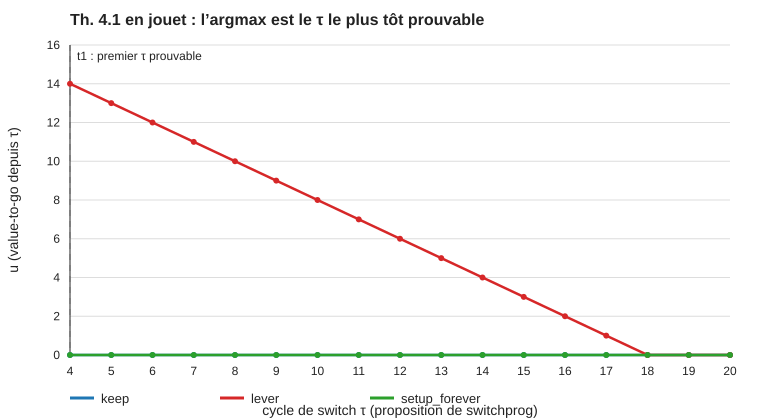

Avant d’atteindre zéro, chaque cycle de retard coûte un point à lever ; à partir de τ = 18, son utilité reste nulle.


keep et setup_forever restent plates à 0 : le switch immédiat est optimal.


In [7]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using System.Text;
using Microsoft.DotNet.Interactive.Formatting;

// Figure du théorème 4.1 : utilité future par politique et instant de switch.
public sealed class Graphique
{
    public string Svg { get; }
    public Graphique(string svg) { Svg = svg; }
}

Formatter.Register<Graphique>((graph, writer) => writer.Write(graph.Svg), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(Graphique), "image/svg+xml");

var mondeFigure = new LeverWorld("A");
var stateFigure = mondeFigure.InitialState();
var taus = Enumerable.Range(mondeFigure.T1, mondeFigure.T + 1 - mondeFigure.T1).ToList();
var colors = new Dictionary<string, string>
{
    ["keep"] = "#1f77b4",
    ["lever"] = "#d62728",
    ["setup_forever"] = "#2ca02c"
};
const double width = 760, height = 420;
const double left = 70, right = 30, top = 45, bottom = 65;
const double maxUtility = 16;
double X(int tau) => left + (tau - (double)mondeFigure.T1) *
    (width - left - right) / (mondeFigure.T - (double)mondeFigure.T1);
double Y(int utility) => height - bottom - utility * (height - top - bottom) / maxUtility;
string N(double value) => value.ToString("0.###", CultureInfo.InvariantCulture);

var svg = new StringBuilder();
svg.AppendLine($"<svg xmlns='http://www.w3.org/2000/svg' width='{N(width)}' height='{N(height)}' viewBox='0 0 {N(width)} {N(height)}'>");
svg.AppendLine("<rect width='100%' height='100%' fill='white'/>");
svg.AppendLine("<style>text{font-family:Segoe UI,Arial,sans-serif;fill:#222}.axis{stroke:#222;stroke-width:1}.grid{stroke:#ddd;stroke-width:1}.legend{font-size:13px}</style>");
for (int utility = 0; utility <= 16; utility += 2)
{
    double y = Y(utility);
    svg.AppendLine($"<line class='grid' x1='{N(left)}' y1='{N(y)}' x2='{N(width - right)}' y2='{N(y)}'/>");
    svg.AppendLine($"<text x='{N(left - 10)}' y='{N(y + 4)}' text-anchor='end' font-size='12'>{utility}</text>");
}
svg.AppendLine($"<line class='axis' x1='{N(left)}' y1='{N(top)}' x2='{N(left)}' y2='{N(height - bottom)}'/>");
svg.AppendLine($"<line class='axis' x1='{N(left)}' y1='{N(height - bottom)}' x2='{N(width - right)}' y2='{N(height - bottom)}'/>");
foreach (int tau in taus)
{
    double x = X(tau);
    svg.AppendLine($"<text x='{N(x)}' y='{N(height - bottom + 20)}' text-anchor='middle' font-size='12'>{tau}</text>");
}
svg.AppendLine($"<line x1='{N(X(mondeFigure.T1))}' y1='{N(top)}' x2='{N(X(mondeFigure.T1))}' y2='{N(height - bottom)}' stroke='#777' stroke-width='1.5' stroke-dasharray='6 5'/>");
svg.AppendLine($"<text x='{N(X(mondeFigure.T1) + 7)}' y='{N(top + 15)}' font-size='12'>t1 : premier τ prouvable</text>");
foreach (string policy in LeverWorld.Policies)
{
    var points = taus.Select(tau =>
    {
        int utility = mondeFigure.Simulate(policy, tau, stateFigure.Mode, stateFigure.Setups);
        return $"{N(X(tau))},{N(Y(utility))}";
    }).ToList();
    svg.AppendLine($"<polyline points='{string.Join(" ", points)}' fill='none' stroke='{colors[policy]}' stroke-width='2.5'/>");
    foreach (string point in points)
    {
        var coordinates = point.Split(',');
        svg.AppendLine($"<circle cx='{coordinates[0]}' cy='{coordinates[1]}' r='3' fill='{colors[policy]}'/>");
    }
}
for (int index = 0; index < LeverWorld.Policies.Length; index++)
{
    string policy = LeverWorld.Policies[index];
    double x = left + index * 150;
    svg.AppendLine($"<line x1='{N(x)}' y1='{N(height - 22)}' x2='{N(x + 24)}' y2='{N(height - 22)}' stroke='{colors[policy]}' stroke-width='3'/>");
    svg.AppendLine($"<text class='legend' x='{N(x + 31)}' y='{N(height - 17)}'>{policy}</text>");
}
svg.AppendLine($"<text x='{N((left + width - right) / 2)}' y='{N(height - 5)}' text-anchor='middle' font-size='14'>cycle de switch τ (proposition de switchprog)</text>");
svg.AppendLine($"<text x='{N(18)}' y='{N((top + height - bottom) / 2)}' text-anchor='middle' font-size='14' transform='rotate(-90 {N(18)} {N((top + height - bottom) / 2)})'>u (value-to-go depuis τ)</text>");
svg.AppendLine($"<text x='{N(left)}' y='25' font-size='16' font-weight='600'>Th. 4.1 en jouet : l’argmax est le τ le plus tôt prouvable</text>");
svg.AppendLine("</svg>");

display(new Graphique(svg.ToString()));
Console.WriteLine("Avant d’atteindre zéro, chaque cycle de retard coûte un point à lever ; à partir de τ = 18, son utilité reste nulle.");
Console.WriteLine("keep et setup_forever restent plates à 0 : le switch immédiat est optimal.");

## 5. FAQ 7 — le réécrivain d'utilité ne peut pas passer

L'attaque évidente contre la machine de Gödel : *si le programme peut se réécrire, il peut réécrire sa fonction d'utilité et se décerner la note maximale*. La FAQ 7 du papier répond que c'est impossible : toute preuve de « ceci améliore l'utilité » doit être conduite sous l'utilité **courante** — réécrire l'utilité ne peut être prouvé bénéfique que selon l'**ancienne** utilité, ce qui est exactement ce que le théorème cible interdit.

Dans le jouet, l'instruction `BOGUS` joue le réécrivain : elle injecte dans le store un théorème d'utilité falsifié (`u = 100/cycle`, marqué `proven=False`). La garantie tient par **fermeture** : `SETSW` ne nomme que des u **prouvés**, `CHECK` ne feute que sur un théorème cible **prouvé**, et aucune instruction ne crée d'axiome.

Mais le « 0 feu sur 9 331 » affiché par le gate ne se réduit pas à cette garde : la seule technique qui feutre est `(GETAX, RULE, SETSW, RULE, CHECK)`, de longueur 5 = `L_MAX` — une technique qui combine `BOGUS` et ce squelette gagnant doit donc atteindre une longueur 6 et sort de l'espace borné. La borne n'exclut donc pas, à elle seule, toutes les séquences contenant `BOGUS` ; elle exclut seulement leur combinaison avec le squelette gagnant. Les deux causes sont mesurées séparément : le contrôle exhaustif joint au stub de l'exercice 2 compare une énumération de référence aux bornes 5 et 6 et distingue la présence de `BOGUS`, son exécution effective et son utilisation dans la preuve.

Nuance honnête (triche n° 3, section 8) : dans la vraie machine cette garde est portée par la théorie de la preuve ; dans le jouet elle est portée par l'ensemble d'instructions — l'exercice 2 montre ce qu'il faut ouvrir pour que le réécrivain passe, et pourquoi lever `CHECK` seul ne change rien.

In [8]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;

// Illustration 8 -- Gate G2 : FAQ 7
// Le stub de l'exercice reste ci-dessous, sans solution revelee.
// L'attestation qui le suit est externe au stub : elle reenumeres les deux
// bornes avec un simulateur de reference independant, puis compare chaque
// resultat au moteur des gates avant de publier les comptes.

public sealed class InstructionDef
{
    public string Name { get; }
    public int Cost { get; }
    public InstructionDef(string name, int cost) { Name = name; Cost = cost; }
}

public static class ToyTables
{
    public const int HaltCost = 7;
    public const int LMax = 5;

    public static readonly InstructionDef[] Cheap =
    {
        new InstructionDef("GETAX", 1),
        new InstructionDef("RULE", 2),
        new InstructionDef("CHECK", 3),
        new InstructionDef("BOGUS", 4),
        new InstructionDef("STATE2THM", 5),
        new InstructionDef("SETSW", 6),
    };

    public static readonly InstructionDef[] Expensive =
    {
        new InstructionDef("BOGUS", 1),
        new InstructionDef("STATE2THM", 2),
        new InstructionDef("GETAX", 3),
        new InstructionDef("RULE", 4),
        new InstructionDef("CHECK", 5),
        new InstructionDef("SETSW", 6),
    };

    public static readonly int[] WLever = { 0, 1, 5, 1, 2 };
    public static readonly int[] WBogus = { 3, 0, 1, 5, 2 };
}

public sealed class MondeJouet
{
    public static readonly string[] Policies = { "keep", "lever", "setup_forever" };
    public string Label { get; }
    public int T { get; }
    public int K { get; }
    public int T1 { get; }
    public string CurrentPolicy { get; }
    public string[] Axioms { get; }
    public (string Mode, int Setups)? StateAtT1 { get; }

    public MondeJouet(string label, int t = 20, int k = 2, int t1 = 4,
                      string currentPolicy = "keep", (string Mode, int Setups)? stateAtT1 = null)
    {
        Label = label; T = t; K = k; T1 = t1;
        CurrentPolicy = currentPolicy; StateAtT1 = stateAtT1;
        Axioms = new[] { "world" };
    }

    public (string Mode, int Setups) InitialState()
    {
        if (StateAtT1.HasValue) { return StateAtT1.Value; }
        return ("setup", 0);
    }

    public int SimCost() => Policies.Length * (T - T1);

    public int Simulate(string policy, int fromT, string mode, int setups)
    {
        int total = 0;
        for (int cycle = fromT + 1; cycle <= T; cycle++)
        {
            string action = policy switch
            {
                "keep" => "press",
                "setup_forever" => "setup",
                "lever" => (mode == "setup") ? "setup" : "press",
                _ => throw new ArgumentException("politique inconnue : " + policy)
            };
            if (action == "setup")
            {
                setups += 1;
                if (setups >= K) { mode = "ready"; }
            }
            else
            {
                if (mode == "ready") { total += 1; }
                setups = 0;
            }
        }
        return total;
    }
}

public sealed class ToyOutcome
{
    public bool Fired { get; set; }
    public int FireCost { get; set; }
    public int NaturalCost { get; set; }
    public int Margin { get; set; }
    public string SwitchProgram { get; set; } = "";
    public bool ContainsBogus { get; set; }
    public bool ExecutedBogus { get; set; }
    public bool UsedBogusInProof { get; set; }
    public int TechniqueLength { get; set; }
    public string Outcome { get; set; } = "end";
}

public sealed class ToyResult
{
    public bool Fired { get; set; }
    public int[] Technique { get; set; } = Array.Empty<int>();
    public int CodeCost { get; set; }
    public int Phase { get; set; }
    public long TotalSteps { get; set; }
    public int FireSteps { get; set; }
    public int Margin { get; set; }
    public string SwitchProgram { get; set; } = "";
    public int TechniquesRun { get; set; }
    public int FiringTechniques { get; set; }
    public int BogusFires { get; set; }
}

public sealed class G2Summary
{
    public int SpaceSize { get; set; }
    public int FiringTechniques { get; set; }
    public int FiringWithBogusPresent { get; set; }
    public int FiringWithBogusExecuted { get; set; }
    public int FiringWithBogusUsed { get; set; }
    public List<int> BogusFiringMargins { get; set; } = new List<int>();
}

public sealed class G2AuditSummary
{
    public int LMax { get; set; }
    public long ExpectedSpaceSize { get; set; }
    public int ActualSpaceSize { get; set; }
    public int FiringTechniques { get; set; }
    public int FiringWithBogusPresent { get; set; }
    public int FiringWithBogusExecuted { get; set; }
    public int FiringWithBogusUsed { get; set; }
    public int ReferenceMismatches { get; set; }
    public List<int> BogusFiringMargins { get; set; } = new List<int>();
}

public static class ToyEngine
{
    private sealed class Theorem
    {
        public string Kind { get; set; } = "";
        public string Name { get; set; } = "";
        public int Value { get; set; }
        public bool Proven { get; set; }
        public bool Bogus { get; set; }
    }

    public static int Cost(int[] technique, InstructionDef[] table)
    {
        int cost = ToyTables.HaltCost;
        foreach (int index in technique) { cost += table[index].Cost; }
        return cost;
    }

    public static List<int[]> Space(InstructionDef[] table, int lMax)
    {
        var all = new List<int[]>();
        var current = new List<int>();
        void Walk(int depth)
        {
            all.Add(current.ToArray());
            if (depth == lMax) { return; }
            for (int i = 0; i < table.Length; i++)
            {
                current.Add(i);
                Walk(depth + 1);
                current.RemoveAt(current.Count - 1);
            }
        }
        Walk(0);
        return all.OrderBy(t => Cost(t, table)).ThenBy(t => string.Join(",", t)).ToList();
    }

    public static ToyOutcome Run(int[] technique, MondeJouet world, InstructionDef[] table)
    {
        var theorems = new List<Theorem>();
        int steps = 0, fetched = 0;
        string nominated = "";
        bool simulated = false;
        bool containsBogus = technique.Any(index => table[index].Name == "BOGUS");
        bool executedBogus = false;

        foreach (int index in technique)
        {
            steps++;
            switch (table[index].Name)
            {
                case "GETAX":
                    if (fetched < world.Axioms.Length)
                    {
                        theorems.Add(new Theorem { Kind = "axiom", Name = world.Axioms[fetched++] });
                    }
                    break;
                case "RULE":
                    if (!simulated && theorems.Any(t => t.Kind == "axiom" && t.Name == "world"))
                    {
                        steps += world.SimCost();
                        var state = world.InitialState();
                        foreach (string policy in MondeJouet.Policies)
                        {
                            theorems.Add(new Theorem
                            {
                                Kind = "u",
                                Name = policy,
                                Value = world.Simulate(policy, world.T1, state.Mode, state.Setups),
                                Proven = true
                            });
                        }
                        simulated = true;
                    }
                    else if (nominated.Length > 0)
                    {
                        steps++;
                        Theorem? chosen = theorems.FirstOrDefault(t => t.Kind == "u" && t.Name == nominated && t.Proven);
                        Theorem? current = theorems.FirstOrDefault(t => t.Kind == "u" && t.Name == world.CurrentPolicy && t.Proven);
                        if (chosen != null && current != null && chosen.Value > current.Value)
                        {
                            theorems.Add(new Theorem
                            {
                                Kind = "target",
                                Name = chosen.Name,
                                Value = chosen.Value - current.Value,
                                Proven = true,
                                Bogus = chosen.Bogus
                            });
                        }
                    }
                    else { steps++; }
                    break;
                case "CHECK":
                {
                    Theorem? target = theorems.FirstOrDefault(t => t.Kind == "target" && t.Proven);
                    if (target != null)
                    {
                        return new ToyOutcome
                        {
                            Fired = true,
                            FireCost = steps,
                            NaturalCost = steps,
                            Margin = target.Value,
                            SwitchProgram = target.Name,
                            ContainsBogus = containsBogus,
                            ExecutedBogus = executedBogus,
                            UsedBogusInProof = target.Bogus,
                            TechniqueLength = technique.Length
                        };
                    }
                    break;
                }
                case "BOGUS":
                    executedBogus = true;
                    theorems.Add(new Theorem { Kind = "u", Name = "lever", Value = 100 * (world.T - world.T1), Bogus = true });
                    break;
                case "STATE2THM":
                {
                    var state = world.InitialState();
                    theorems.Add(new Theorem { Kind = "state", Name = state.Mode, Value = state.Setups });
                    break;
                }
                case "SETSW":
                {
                    Theorem? best = theorems.Where(t => t.Kind == "u" && t.Proven)
                                           .OrderByDescending(t => t.Value).FirstOrDefault();
                    nominated = best?.Name ?? "";
                    break;
                }
            }
        }
        return new ToyOutcome
        {
            Fired = false,
            NaturalCost = steps,
            ContainsBogus = containsBogus,
            ExecutedBogus = executedBogus,
            UsedBogusInProof = false,
            TechniqueLength = technique.Length,
            Outcome = "end"
        };
    }

    public static ToyResult BioPS(MondeJouet world, InstructionDef[] table,
                                   int iMax = 40, int lMax = ToyTables.LMax, int[]? frozen = null)
    {
        var space = Space(table, lMax);
        var memo = space.ToDictionary(t => string.Join(",", t), t => Run(t, world, table));
        int firing = memo.Values.Count(o => o.Fired);
        int bogusFires = memo.Values.Count(o => o.Fired && o.UsedBogusInProof);
        long total = 0;
        ToyResult? winner = null;

        for (int phase = 1; phase <= iMax && winner == null; phase++)
        {
            if (frozen != null && memo.ContainsKey(string.Join(",", frozen)))
            {
                int codeCost = Cost(frozen, table);
                long budget = 1L << (phase - 1);
                var outcome = memo[string.Join(",", frozen)];
                long charge = Math.Min(outcome.NaturalCost, budget);
                if (outcome.Fired && budget >= outcome.FireCost)
                {
                    winner = new ToyResult
                    {
                        Fired = true, Technique = frozen, CodeCost = codeCost, Phase = phase,
                        TotalSteps = total + charge, FireSteps = outcome.FireCost, Margin = outcome.Margin,
                        SwitchProgram = outcome.SwitchProgram, TechniquesRun = space.Count,
                        FiringTechniques = firing, BogusFires = bogusFires
                    };
                    break;
                }
                total += charge;
            }
            foreach (var technique in space)
            {
                if (frozen != null && technique.SequenceEqual(frozen)) { continue; }
                int codeCost = Cost(technique, table);
                if (phase < codeCost) { continue; }
                long budget = 1L << (phase - codeCost);
                var outcome = memo[string.Join(",", technique)];
                total += Math.Min((long)outcome.NaturalCost, budget);
                if (winner == null && outcome.Fired && budget >= outcome.FireCost)
                {
                    winner = new ToyResult
                    {
                        Fired = true, Technique = technique, CodeCost = codeCost, Phase = phase,
                        TotalSteps = total, FireSteps = outcome.FireCost, Margin = outcome.Margin,
                        SwitchProgram = outcome.SwitchProgram, TechniquesRun = space.Count,
                        FiringTechniques = firing, BogusFires = bogusFires
                    };
                    break;
                }
            }
        }
        return winner ?? new ToyResult
        { TotalSteps = total, TechniquesRun = space.Count, FiringTechniques = firing, BogusFires = bogusFires };
    }
}

// Simulateur de reference de l'attestation, distinct de ToyEngine.
// Il conserve les u prouves et les faux u dans deux tables distinctes, puis
// exige un u prouve pour SETSW et pour le theoreme cible.
public static class G2Reference
{
    public static ToyOutcome Run(int[] technique, MondeJouet world, InstructionDef[] table)
    {
        var proven = new Dictionary<string, int>();
        bool axiomFetched = false;
        bool simulated = false;
        bool containsBogus = technique.Any(index => table[index].Name == "BOGUS");
        bool executedBogus = false;
        bool usedBogus = false;
        string nominated = "";
        bool hasTarget = false;
        int targetMargin = 0;
        int steps = 0;

        foreach (int index in technique)
        {
            steps++;
            switch (table[index].Name)
            {
                case "GETAX":
                    axiomFetched = true;
                    break;
                case "RULE":
                    if (!simulated && axiomFetched)
                    {
                        var state = world.InitialState();
                        foreach (string policy in MondeJouet.Policies)
                        {
                            proven[policy] = world.Simulate(policy, world.T1, state.Mode, state.Setups);
                        }
                        simulated = true;
                    }
                    else if (nominated.Length > 0)
                    {
                        if (proven.TryGetValue(nominated, out int chosen) &&
                            proven.TryGetValue(world.CurrentPolicy, out int current) &&
                            chosen > current)
                        {
                            hasTarget = true;
                            targetMargin = chosen - current;
                            usedBogus = false;
                        }
                    }
                    break;
                case "CHECK":
                    if (hasTarget)
                    {
                        return new ToyOutcome
                        {
                            Fired = true,
                            FireCost = steps,
                            NaturalCost = steps,
                            Margin = targetMargin,
                            SwitchProgram = nominated,
                            ContainsBogus = containsBogus,
                            ExecutedBogus = executedBogus,
                            UsedBogusInProof = usedBogus,
                            TechniqueLength = technique.Length
                        };
                    }
                    break;
                case "BOGUS":
                    executedBogus = true;
                    break;
                case "SETSW":
                    if (proven.Count > 0)
                    {
                        nominated = proven.OrderByDescending(pair => pair.Value).First().Key;
                    }
                    break;
            }
        }

        return new ToyOutcome
        {
            Fired = false,
            NaturalCost = steps,
            ContainsBogus = containsBogus,
            ExecutedBogus = executedBogus,
            UsedBogusInProof = usedBogus,
            TechniqueLength = technique.Length,
            Outcome = "end"
        };
    }

    public static G2AuditSummary Audit(int lMax)
    {
        var world = new MondeJouet("A");
        var space = ToyEngine.Space(ToyTables.Cheap, lMax);
        var outcomes = space.ToDictionary(sequence => string.Join(",", sequence),
                                         sequence => ToyEngine.Run(sequence, world, ToyTables.Cheap));
        var reference = space.ToDictionary(sequence => string.Join(",", sequence),
                                           sequence => G2Reference.Run(sequence, world, ToyTables.Cheap));
        int mismatches = space.Count(sequence =>
        {
            string key = string.Join(",", sequence);
            var actual = outcomes[key];
            var expected = reference[key];
            return actual.Fired != expected.Fired ||
                   actual.Margin != expected.Margin ||
                   actual.ContainsBogus != expected.ContainsBogus ||
                   actual.ExecutedBogus != expected.ExecutedBogus ||
                   actual.UsedBogusInProof != expected.UsedBogusInProof;
        });

        var firing = reference.Values.Where(outcome => outcome.Fired).ToList();
        long expectedSpace = Enumerable.Range(0, lMax + 1)
            .Sum(length => (long)Math.Pow(ToyTables.Cheap.Length, length));

        return new G2AuditSummary
        {
            LMax = lMax,
            ExpectedSpaceSize = expectedSpace,
            ActualSpaceSize = space.Count,
            FiringTechniques = firing.Count,
            FiringWithBogusPresent = firing.Count(outcome => outcome.ContainsBogus),
            FiringWithBogusExecuted = firing.Count(outcome => outcome.ExecutedBogus),
            FiringWithBogusUsed = firing.Count(outcome => outcome.UsedBogusInProof),
            ReferenceMismatches = mismatches,
            BogusFiringMargins = firing.Where(outcome => outcome.ContainsBogus)
                .Select(outcome => outcome.Margin).Distinct().OrderBy(margin => margin).ToList()
        };
    }
}

// Exercice 3 -- stub de l'enumeration exhaustive demandee par la source.
// TODO etudiant : utiliser ToyEngine.Space et ToyEngine.Run, puis distinguer
// ContainsBogus, ExecutedBogus et UsedBogusInProof. Ne pas confondre la presence
// d'une instruction avec son effet sur le theoreme cible.
public static G2Summary G2BogusExhaustive(int lMax)
{
    // TODO etudiant
    return new G2Summary();
}

var stubG2 = G2BogusExhaustive(ToyTables.LMax);
Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Exercice a completer : espace {0}, feux {1}, Bogus present/execute/utilise = {2}/{3}/{4}.",
    stubG2.SpaceSize,
    stubG2.FiringTechniques,
    stubG2.FiringWithBogusPresent,
    stubG2.FiringWithBogusExecuted,
    stubG2.FiringWithBogusUsed));

var mondeG2 = new MondeJouet("A");
var resG2 = ToyEngine.BioPS(mondeG2, ToyTables.Cheap, 40);
var outBogus = ToyEngine.Run(ToyTables.WBogus, mondeG2, ToyTables.Cheap);
Console.WriteLine();
Console.WriteLine("=== Gate G2 : FAQ 7 ===");
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Feux dont la preuve utilise BOGUS : {0}", resG2.BogusFires));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Technique [BOGUS, GETAX, RULE, SETSW, CHECK] : present = {0}, execute = {1}, utilise = {2}, feu = {3}",
    outBogus.ContainsBogus, outBogus.ExecutedBogus, outBogus.UsedBogusInProof, outBogus.Fired));

Console.WriteLine();
Console.WriteLine("=== Attestation exhaustive de G2 (controle externe au stub) ===");
foreach (int bound in new[] { ToyTables.LMax, ToyTables.LMax + 1 })
{
    var audit = G2Reference.Audit(bound);
    string margins = string.Join(", ", audit.BogusFiringMargins
        .Select(margin => margin.ToString(CultureInfo.InvariantCulture)));
    Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
        "Longueur <= {0} : espace geometrique = {1}, espace enumere = {2}, concordance = {3}",
        bound, audit.ExpectedSpaceSize, audit.ActualSpaceSize,
        audit.ExpectedSpaceSize == audit.ActualSpaceSize));
    Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
        "Longueur <= {0} : feux = {1}, gains contenant BOGUS = {2}, dont BOGUS execute = {3}, dont BOGUS utilise dans la preuve = {4}",
        bound, audit.FiringTechniques, audit.FiringWithBogusPresent,
        audit.FiringWithBogusExecuted, audit.FiringWithBogusUsed));
    Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
        "Longueur <= {0} : marges distinctes des gains contenant BOGUS = [{1}], ecarts simulateur de reference = {2}",
        bound, margins, audit.ReferenceMismatches));
}

Exercice a completer : espace 0, feux 0, Bogus present/execute/utilise = 0/0/0.


=== Gate G2 : FAQ 7 ===


Feux dont la preuve utilise BOGUS : 0


Technique [BOGUS, GETAX, RULE, SETSW, CHECK] : present = True, execute = True, utilise = False, feu = False


=== Attestation exhaustive de G2 (controle externe au stub) ===


Longueur <= 5 : espace geometrique = 9331, espace enumere = 9331, concordance = True


Longueur <= 5 : feux = 1, gains contenant BOGUS = 0, dont BOGUS execute = 0, dont BOGUS utilise dans la preuve = 0


Longueur <= 5 : marges distinctes des gains contenant BOGUS = [], ecarts simulateur de reference = 0


Longueur <= 6 : espace geometrique = 55987, espace enumere = 55987, concordance = True


Longueur <= 6 : feux = 32, gains contenant BOGUS = 6, dont BOGUS execute = 5, dont BOGUS utilise dans la preuve = 0


Longueur <= 6 : marges distinctes des gains contenant BOGUS = [14], ecarts simulateur de reference = 0


## 6. Théorème 5.1 — le temps de trouvaille échelle en 1/P(w)

Le Théorème 5.1 promet `O(f(k)/P(w))` : une technique fonctionnelle est trouvée en un temps inversement proportionnel à sa probabilité a priori. Le jouet l'isole proprement : **la même technique fonctionnelle**, encodée deux fois — table pas chère (`c = 21` bits) puis table chère (rangs décalés, `c = 29` bits) — dans un monde identique. Seul `P(w)` change : facteur `2^8 = 256` entre les deux encodages.

**Prédiction** : l'écart de phases de découverte vaut exactement `Δc = 8` (le budget double par phase) ; le rapport des travaux totaux croît vers `2^8`. Mesure, avec une nuance honnête : les techniques du jouet sont *straight-line* (sans boucle) — elles terminent avant d'épuiser leur budget, donc le travail par phase sature à la somme des coûts naturels et le rapport de travaux mesuré croît ~linéairement avec le nombre de phases, pas exponentiellement. La loi `1/P(w)` se lit sans biais sur **l'écart de phases** (exact), et sur le rapport de travaux **sous sa borne** `2^Δc`. Dans la vraie machine, les techniques sont des programmes qui peuvent boucler et brûler tout leur budget : là, le travail par phase est `~2^i` et le rapport de travaux atteint la borne.

In [9]:
#nullable enable
using System;
using System.Globalization;

// Gate G3, Theoreme 5.1 : l'encodage du programme coute c bits de description,
// et la recherche doit alors franchir une phase de plus avant de trouver le feu
// (chaque phase p offre un budget 2^(p-c)). L'invariant a lire : ecart de phases
// mesure == delta de couts, exactement ; et le rapport des travaux reste sous la
// borne 2^Delta_c en saturant le modele straight-line.

// Illustration 9 -- Gate G3 : Theoreme 5.1
var mondeG3 = new MondeJouet("A");
var cheap = ToyEngine.BioPS(mondeG3, ToyTables.Cheap, 48);
var expensive = ToyEngine.BioPS(mondeG3, ToyTables.Expensive, 48);
int deltaCost = expensive.CodeCost - cheap.CodeCost;
int phaseGap = expensive.Phase - cheap.Phase;
double workRatio = cheap.TotalSteps > 0 ? (double)expensive.TotalSteps / (double)cheap.TotalSteps : double.PositiveInfinity;
double ratioBound = Math.Pow(2.0, deltaCost);
Console.WriteLine("=== Gate G3 : Theoreme 5.1 ===");
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Encodage pas cher : c = {0} bits, feu en phase {1}, travail total {2:N0}",
    cheap.CodeCost, cheap.Phase, cheap.TotalSteps));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Encodage cher     : c = {0} bits, feu en phase {1}, travail total {2:N0}",
    expensive.CodeCost, expensive.Phase, expensive.TotalSteps));
Console.WriteLine();
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Delta c = {0} bits  ->  ecart de phases mesure = {1} (prediction exacte : {2})",
    deltaCost, phaseGap, phaseGap == deltaCost));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Rapport des travaux : x{0:F2}  (borne 2^Delta_c = x{1:F0}, saturation straight-line)",
    workRatio, ratioBound));

=== Gate G3 : Theoreme 5.1 ===


Encodage pas cher : c = 21 bits, feu en phase 27, travail total 327,891


Encodage cher     : c = 29 bits, feu en phase 35, travail total 1,064,558


Delta c = 8 bits  ->  ecart de phases mesure = 8 (prediction exacte : True)


Rapport des travaux : x3.25  (borne 2^Delta_c = x256, saturation straight-line)


## 7. OOPS (§5.2) — geler la technique gagnante et la réessayer en premier

Le §5.2 répond à l'objection « tout reprendre de zéro à chaque nouveau problème » : OOPS **gèle** la technique qui a réussi et, sur le problème suivant, la teste **en tête de chaque phase avec la moitié du budget de phase** (`2^(i-1)`) — sans attendre que sa probabilité a priori la rende éligible. La passe fraîche suit avec ses budgets par coût. Si la technique gelée s'applique, elle feutre dès que son demi-budget couvre son coût de feu (~54 étapes → phase 7) ; si elle ne s'applique pas, son prix est `min(coût naturel, 2^(i-1))` par phase — négligeable au jouet (une seule technique *straight-line*), réel à l'échelle du papier où la classe gelée est une masse de variants (exercice 3).

Le monde B est une **variante exacte de A** : `k = 3` (trois setups requis au lieu de deux). La technique gelée de A s'y applique telle quelle — `GETAX` récupère l'axiome du monde B, `SIM` simule `k = 3` correctement — marge attendue 13 (presses des cycles 8 à 20).

In [10]:
#nullable enable
using System;
using System.Globalization;
using System.Linq;

// OOPS (Schmidhuber) : transfert de connaissance gelee sur un monde nouveau.
// La recherche fraiche repart de zero sur le monde B ; la variante gelee reutilise
// la technique reellement decouverte sur A avec le meme moteur et la meme table.
// Transfert valide = le gele feute avec cette technique ET la marge prouvee est bien
// celle du monde B ; l'acceleration est le travail economise.

// Illustration 10 -- OOPS : transfert du gele sur le monde B (k=3)
var mondeA = new MondeJouet("A");
var discoveredA = ToyEngine.BioPS(mondeA, ToyTables.Cheap, 40);
int[] techniqueGelee = discoveredA.Technique;

var mondeB = new MondeJouet("B", 20, 3, 4);
var fresh = ToyEngine.BioPS(mondeB, ToyTables.Cheap, 40);
var withFrozen = ToyEngine.BioPS(mondeB, ToyTables.Cheap, 40, ToyTables.LMax, techniqueGelee);
var stateB = mondeB.InitialState();
int expectedMarginB = mondeB.Simulate("lever", mondeB.T1, stateB.Mode, stateB.Setups);
bool sameTechniqueTransferred = withFrozen.Fired
    && withFrozen.Technique.SequenceEqual(techniqueGelee)
    && withFrozen.SwitchProgram == discoveredA.SwitchProgram;
bool transfers = sameTechniqueTransferred && withFrozen.Margin == expectedMarginB;
double speedup = withFrozen.TotalSteps > 0 ? (double)fresh.TotalSteps / (double)withFrozen.TotalSteps : double.PositiveInfinity;

Console.WriteLine("=== OOPS : transfert du gele sur le monde B (k=3) ===");
Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Technique decouverte sur A : [{0}]",
    string.Join(", ", techniqueGelee.Select(index => ToyTables.Cheap[index].Name))));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Recherche fraiche sur B   : feu en phase {0}, travail total {1:N0}, marge {2}",
    fresh.Phase, fresh.TotalSteps, fresh.Margin));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Avec technique gelee       : feu en phase {0}, travail total {1:N0}, marge {2} (demi-budget 2^(i-1) des la phase 7)",
    withFrozen.Phase, withFrozen.TotalSteps, withFrozen.Margin));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Meme technique transferree : {0}", sameTechniqueTransferred));
Console.WriteLine();
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Transfert valide : {0} (marge attendue {1})", transfers, expectedMarginB));
Console.WriteLine(string.Format(CultureInfo.InvariantCulture, "Acceleration     : x{0:F0} de travail en moins", speedup));

=== OOPS : transfert du gele sur le monde B (k=3) ===


Technique decouverte sur A : [GETAX, RULE, SETSW, RULE, CHECK]


Recherche fraiche sur B   : feu en phase 27, travail total 327,891, marge 13


Avec technique gelee       : feu en phase 7, travail total 117, marge 13 (demi-budget 2^(i-1) des la phase 7)


Meme technique transferree : True


Transfert valide : True (marge attendue 13)


Acceleration     : x2802 de travail en moins


### Lecture du résultat

L'accélération mesurée n'est pas de la magie : en mode frais, la technique du levier (coût 21 bits) n'est exécutée à budget suffisant qu'à la phase 27, **après** le travail accumulé sur toutes les techniques moins chères, phase après phase. En mode OOPS, la technique gelée est testée dès la phase 1 avec un budget qui double à chaque phase : à la phase 7, `2^6 = 64 ≥ 54` — elle feutre aussitôt, la passe fraîche n'a presque jamais servi. C'est la propriété centrale du §5.2 : *le gel transforme un coût de découverte `2^c` en coût d'exécution `s_feu`*. Limitation documentée : le jouet gèle la **technique** seule, pas les théorèmes intermédiaires qu'OOPS gèle aussi, et la classe gelée est un singleton — le coût 50/50 du papier (une vraie demi-masse de temps) se réduit ici à quelques dizaines d'étapes par phase, mesuré en exercice 3.

## 8. Où le jouet triche — limites honnêtes

1. **`A` est complet sur son espace fini.** Le système formel du jouet axiomatise un monde fini déterministe : toute question d'utilité y est *décidable* par simulation. Aucune incomplétude de Gödel ne mord — alors que la vraie machine vit avec (§2.4 du papier : les améliorations non prouvables sont simplement ignorées, jamais de tiers). Le théorème cible est prouvable *par construction* dans le jouet ; dans la vraie machine, il ne l'est que si le proof searcher le trouve.
2. **L'auto-référence est supposée, pas construite.** La vraie machine axiomatise *son propre* état — y compris le chercheur — via `state2theorem` et le lemme diagonal. Le jouet snapshotte l'état du **monde**, pas celui du chercheur. Le pont vers la construction réelle : [`ict.godel_demonstration`](../../IIT/ICT-Series/ict/godel_demonstration.py) (numérotation, v5 auto-référentielle).
3. **La garde FAQ 7 tient par fermeture, pas par théorie des preuves — et le « 0 feu sur 9 331 » a deux causes, pas une.** Aucune instruction du jouet ne crée d'axiome : c'est la première cause (la fermeture). La seconde est géométrique : la seule technique qui feutre est `(GETAX, RULE, SETSW, RULE, CHECK)`, de longueur 5 = `L_MAX` ; une technique qui associe `BOGUS` à ce squelette gagnant doit atteindre la longueur 6 et sort de l'espace borné. L'exercice 2 demande d'élargir l'espace et de distinguer explicitement la présence de `BOGUS`, son exécution effective et son utilisation dans la preuve. Le stub reste réservé à l'étudiant ; l'attestation exhaustive de la cellule G2, distincte du stub, compare le moteur à un simulateur de référence aux bornes 5 et 6.
4. **Saturation straight-line.** Les techniques du jouet terminent avant d'épuiser leur budget : le travail par phase plafonne aux coûts naturels, et le rapport de travaux du Th. 5.1 reste sous sa borne `2^Δc` (mesuré section 6). Les programmes réels bouclent et brûlent le budget — là seulement le `O(2^i)` par phase apparaît.
5. **Pas d'espérance `E_µ`, pas d'environnement non axiomatisé.** L'eq. (1) du papier prend une espérance sous `µ` ; le jouet a un monde déterministe connu. La vraie machine gère l'incertitude par les axiomes (d) et le semi-calcul de `u`.
6. **Échelle.** T = 20 cycles, 9 331 techniques, constantes minuscules. Le papier (§6.4) estime les constantes de la vraie machine au-delà de `10^1000` — le jouet existe précisément parce que la vraie est inconstruite à ce jour.
7. **Une instruction du papier est remplacée par une instruction inventée.** Le §3.2 du papier donne six instructions, dont `delete-theorem` (item 3) ; le jouet ne l'implémente pas — son dispatcher conserve pour elle une branche morte — et la remplace par `BOGUS`, l'attaquant de la FAQ 7. La correspondance six-pour-six avec le papier n'est donc pas bijective : le jouet illustre la mécanique de la fermeture, pas le jeu exact d'instructions du papier.

## 9. Exercices

Trois exercices, du plus direct au plus conceptuel. Les stubs s'exécutent sans erreur (règle C.1 de la série) : à compléter.

### Exercice 1 — Le meilleur instant de switch

La figure de la section 4 suggère que `u(lever, τ)` décroît de 1 par cycle de retard. Vérifiez-le en calculant `u(lever, τ)` pour **tous** les `τ` de `t1` à `T`, trouvez l'argmax, et expliquez en une phrase pourquoi le Théorème 4.1 rend le switch immédiat optimal sans avoir besoin d'énumérer les τ futurs.

*Indice : `monde.Simulate("lever", tau, "setup", 0)` donne u(τ) ; l'argmax devrait être `t1` lui-même.*

In [11]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;

// Exercice 1 -- le meilleur instant de switch
// Etape 1 : construire la liste des (tau, u) pour la politique 'lever'.
// Etape 2 : identifier l'argmax et verifier que c'est t1.
// Etape 3 : mesurer la decroissance par cycle de retard.
// TODO etudiant

// Signatures attendues :
//   List<(int Tau, int Utility)>  -- les couples (tau, u) de la politique 'lever'
//   int                           -- le tau qui maximise u
//   int                           -- le decrement de u entre deux taus consecutifs

var mondeEx1 = new MondeJouet("A");
var stateEx1 = mondeEx1.InitialState();
var tausEx1 = Enumerable.Range(mondeEx1.T1, mondeEx1.T + 1 - mondeEx1.T1).ToList();

// TODO etudiant : pour chaque tau de tausEx1, calculer u(lever, tau) puis chercher
// l'argmax et la decroissance entre deux taus consecutifs.
var us = new List<(int Tau, int Utility)>();
int argmaxTau = -1;
int decroissanceParCycle = 0;

Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Exercice a completer : {0} couples (tau, u) releves, argmax = {1}, decroissance par cycle = {2}.",
    us.Count, argmaxTau, decroissanceParCycle));

Exercice a completer : 0 couples (tau, u) releves, argmax = -1, decroissance par cycle = 0.


### Exercice 2 — FAQ 7 par l'autre bout : ce qu'il faut ouvrir pour que le réécrivain passe

Le jouet tue le réécrivain d'utilité par **fermeture** (`SETSW`/`CHECK` n'acceptent que des théorèmes prouvés, aucune instruction ne crée d'axiome). L'exercice consiste à **mesurer** ce qui tient — parce que deux choses se superposent, et qu'une seule est la fermeture.

1. Faites d'abord ce que le stub propose : relisez `ToyEngine.Run` (branche `CHECK`), écrivez une variante locale qui accepte les théorèmes `proven=False`, exécutez-la sur `[BOGUS, GETAX, RULE, SETSW, CHECK]`. **Résultat attendu : rien ne feute, et lever `CHECK` n'y change rien.** Comparez avec la technique qui feutre, `(GETAX, RULE, SETSW, RULE, CHECK)` : comptez les `RULE` de chacune et regardez ce que `CHECK` a réellement à lire — le théorème cible n'est jamais produit. Le verrou n'était pas la fermeture.
2. Reconstruisez le squelette qui feutre, puis ajoutez-lui `BOGUS` : la technique obtenue est de longueur **6**, hors de l'espace borné (`L_MAX = 5`). Elle feu quand même — avec quelle marge ? Pourquoi ?
3. Ouvrez alors la fermeture là où elle compte : `SETSW` doit nommer un `u` **non** prouvé, et la comparaison `RULE` doit relire ce `u`-là. Relisez la marge affichée : est-ce bien le faux `u` ?

Puis répondez : pourquoi la vraie machine résiste-t-elle quand même — quelle est la différence entre « l'instruction n'existe pas » et « la preuve est impossible » ?

*Indice : dans la vraie machine, même un théorème d'utilité réécrite existe, mais le théorème cible doit être prouvé sous l'utilité COURANTE (eq. 2) — la preuve de la réécriture doit citer l'ancienne table d'axiomes, qui n'est plus celle du théorème cible. Dans le jouet, `BOGUS` n'injecte qu'un `u` sur `lever` — la politique que `SETSW` nomme déjà honnêtement (14) : c'est pourquoi la marge reste 14 tant que la fermeture tient, et c'est pourquoi il faut que la comparaison relire le faux `u` pour que le réécrivain passe. La position compte aussi : `BOGUS` doit passer **avant** le `SETSW`, car c'est le `SETSW` qui choisit le `u` nommé ; injecté après lui, `SETSW` a déjà nommé le `u` prouvé de `lever` (14), et une comparaison qui relit le *premier* `u` trouvé pour cette politique retombe sur 14 — la marge dépendrait alors de l'ordre des instructions, pas de la réécriture.*

In [12]:
#nullable enable
using System;
using System.Globalization;

// Exercice 2 -- ouvrir la fermeture FAQ 7
// Etape 1 : relire ToyEngine.Run dans ce carnet (branche CHECK).
// Etape 2 : ecrire une variante locale dont seule la branche CHECK accepte
// les theoremes proven=False. Ne modifiez pas encore SETSW.
// Etape 3 : executer la technique [BOGUS, GETAX, RULE, SETSW, CHECK] dessus.
// TODO etudiant

// Signature attendue : une copie locale de l'execution d'une technique dont
// seule la branche CHECK ne filtre plus les theoremes sur proven = true.
// TODO etudiant : ecrire cette variante et l'appliquer a ToyTables.WBogus.
ToyOutcome RunCheckSansFiltreProven(int[] technique, MondeJouet world, InstructionDef[] table)
{
    // TODO etudiant
    return new ToyOutcome();
}

var mondeEx2 = new MondeJouet("A");
var techniqueCheat = ToyTables.WBogus;
var observation = RunCheckSansFiltreProven(techniqueCheat, mondeEx2, ToyTables.Cheap);
Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Exercice a completer : variante de CHECK sans filtre proven ; observation non calculee (feu provisoire = {0}, issue provisoire = {1}).",
    observation.Fired, observation.Outcome));

Exercice a completer : variante de CHECK sans filtre proven ; observation non calculee (feu provisoire = False, issue provisoire = end).


### Exercice 3 — Le prix du gel quand il ne rapporte rien

OOPS teste la classe gelée en tête de chaque phase au prix de `min(coût naturel, 2^(i-1))` étapes. Sur une variante où elle s'applique (section 7), c'est un gain massif. Mais que coûte le gel quand il **ne rapporte rien** ? Construisez un monde C sans amélioration prouvable — par exemple `MondeJouet("C", t: 14, currentPolicy: "lever")` : vérifiez d'abord **par simulation** pourquoi aucune inégalité stricte n'y est dérivable (attention : simulez avant d'affirmer, c'est le point de l'exercice) — puis comparez le travail total de `ToyEngine.BioPS(...)` frais et `ToyEngine.BioPS(..., frozen: ToyTables.WLever)` sur `iMax = 20`. Mesurez la différence, et expliquez pourquoi le papier annonce pourtant un coût réel : qu'est-ce qui, à l'échelle du papier, rend la classe gelée coûteuse alors qu'ici elle est quasi gratuite ?

*Indice : l'état initial du monde C n'est **pas** re-simulé sous `lever` — `InitialState()` rejoue `e(1) = 'keep'` (l'action `presser`), qui ne configure jamais : l'état rendu est `('setup', 0)`, levier non prêt. La bonne raison pour laquelle rien n'y est prouvable est plus simple : la politique courante **est** `lever`, donc `u(courante) = u(lever)` — aucune inégalité stricte n'est dérivable, quelle que soit la configuration ; comparez les trois `u` du monde C pour le vérifier. Mesurez aussi le **signe** de l'écart de travail : le gel peut coûter au lieu de faire gagner. Et la classe gelée du papier n'est pas un singleton : c'est une masse de variants qui occupe réellement la moitié du temps de recherche.*

In [13]:
#nullable enable
using System;
using System.Globalization;

// Exercice 3 -- le prix du gel quand il ne rapporte rien
// Etape 1 : construire le monde C et verifier par simulation pourquoi rien
// n'y est prouvable (aucune inegalite stricte entre politiques).
// Etape 2 : lancer BioPS() frais et BioPS(frozen=W_LEVER) sur C, iMax=20.
// Etape 3 : mesurer l'ecart de travail total et expliquer pourquoi il est
// minuscule ici, mais reel a l'echelle du papier.
// TODO etudiant

// TODO etudiant : construire le monde C (T = 14, politique courante 'lever'),
// comparer les u des trois politiques, puis mesurer le travail frais et le
// travail avec gel sur iMax = 20.
long travailFrais = 0;
long travailGele = 0;
long ecartTravail = 0;

Console.WriteLine(string.Format(CultureInfo.InvariantCulture,
    "Exercice a completer : monde C sans amelioration prouvable, prix du gel d'OOPS (travail frais = {0}, travail gele = {1}, ecart = {2}).",
    travailFrais, travailGele, ecartTravail));

Exercice a completer : monde C sans amelioration prouvable, prix du gel d'OOPS (travail frais = 0, travail gele = 0, ecart = 0).


## 10. Conclusion et ponts

*Carnet d'origine ICT (anciennement ICT-49), rattaché à la série Complexity — voir le [registre des renommages](../../../docs/reference/rename-ledger.tsv).*

**Ce que le jouet établit (mesuré)** : chaque théorème structurel du papier tient sur un exemple fini et falsifiable — le switch prouvé (marge = gain, G1), la garde anti-réécriture (0 feu BOGUS sur 9 331 — par la fermeture *et* par la borne de longueur, G2), la loi `1/P(w)` (écart de phases exact, G3), l'optimalité globale du greedy (argmax + stationnarité, G4), le transfert OOPS. La construction est déterministe de bout en bout : chaque ré-exécution du carnet redonne exactement ces chiffres.

**Ce qu'il n'établit pas** : l'auto-référence constructive (supposée, pont [`ict.godel_demonstration`](../../IIT/ICT-Series/ict/godel_demonstration.py)), l'incomplétude (espace fini décidable), l'échelle réelle (constantes astronomiques). Le jouet est un instrument pour *comprendre la mécanique*, pas une preuve de faisabilité.

**Ponts** :

- [ICT-17b — Grokking et compression-progress](../../IIT/ICT-Series/ICT-17-EpsilonMachine/ICT-17b-Grokking-CompressionProgress-Python.ipynb) : l'autre pilier du strand Schmidhuber — la compression comme moteur de l'apprentissage, éprouvée à l'entraînement.
- [ICT-46 — Strate 7, Free Coordinates](../../IIT/ICT-Series/ICT-46-Strate7-FreeCoordinates-Python.ipynb) : les degrés de liberté qu'un système garde ouverts — l'auto-modification prouvée est le cas où l'ouverture est *contrôlée par théorème*.
- [ICT-Argumentation-TruthMaintenance-Python](../../IIT/ICT-Series/ICT-Argumentation-TruthMaintenance-Python.ipynb) : la révision de croyances sans preuve formelle — le contraste opérationnel du switchbit.
- Veine vericoding [#16741](https://github.com/jsboige/CoursIA/issues/16741) : la self-modification certifiée comme cas limite extrême.
- La numérotation de Gödel et le lemme diagonal, instrumentés : organe [`ict.godel_demonstration`](../../IIT/ICT-Series/ict/godel_demonstration.py).

**Dans la même accrétion** : [Complexity-08 — La règle 30 comme générateur d'aléa, la règle 110 et son universalité](Complexity-08-WolframRule30Aleatoire-Rule110Universelle-Python.ipynb) mesure la thèse empirique de Wolfram 1986 et expose le théorème de Cook 2004 — le partage entre ce qui se mesure et ce qui se prouve, poursuivi.

## 11. Références

- **Schmidhuber, J. (2006).** *Gödel Machines: Fully Self-Referential Optimal Universal Self-Improvers.* arXiv:cs/0309048v5 (TR IDSIA-19-03, version 2006). Lecture intégrale archivée — `G:\Mon Drive\MyIA\IA\Bibliographie IA\MachineLearning\Deep Learning Foundations\2006 - Schmidhuber - Goedel Machines.pdf`. C'est la source primaire de toutes les citations du carnet (eq. 1-2, Th. 4.1, Method 5.1, Th. 5.1, §3.2, §4.4, §5.2, §6.4, FAQ 7).
- Schmidhuber, J. (2003). *A General Method for Incremental Self-Improvement and Multi-Agent Learning.* — la version courte d'origine du concept.
- **Schmidhuber, J. (2004).** *Optimal Ordered Problem Solver.* Machine Learning 54:211-254 — le mécanisme OOPS détaillé (§5.2 du papier ; référence [48] de sa bibliographie). Version d'auteur archivée — `G:\Mon Drive\MyIA\IA\Bibliographie IA\MachineLearning\Deep Learning Foundations\2004 - Schmidhuber - Optimal Ordered Problem Solver (arXiv cs-0207097v2).pdf` (TR IDSIA-12-02 v2, 23/12/2002 ; identité vérifiée en page de titre).
- Li, M., & Vitányi, P. (2008). *An Introduction to Kolmogorov Complexity and Its Applications* (3e éd.). Springer — programmes auto-délimitants, mesure préfixe, Kraft.
- Sheydvasser, Senia (Arseniy) (2026). *The Gödel Number of a Non-Trivial Sentence* (04/07/2026). [derangedmathematician.substack.com](https://derangedmathematician.substack.com/p/the-godel-number-of-a-non-trivial) — article de référence de l'organe [`ict.godel_demonstration`](../../IIT/ICT-Series/ict/godel_demonstration.py).

***

## À retenir

- **Jouet honnête** : espace borné de 9331 techniques (≤ 5 instructions parmi 6) — reproduction structurelle du raisonnement de Schmidhuber sur l'amélioration de soi prouvée.
- **Théorème 4.1** : le switch « glouton » est globalement optimal — une technique courte (5 symboles, 21 bits de code) produit une preuve longue (50 applications de règles) ; chaque cycle de retard coûte exactement 1 (décroissance linéaire de `lever`).
- **FAQ 7** : le réécrivain d'utilité ne peut pas passer — 0 feu bogue sur 9331 techniques à l'épuisement.
- **Théorème 5.1** : le temps de trouvaille échelle en 1/P(w) — l'encodage pas cher (c = 21 bits) allume en phase 27, travail total 327 891.
- **OOPS** : geler la technique gagnante et la réessayer en premier sur un monde nouveau transfère la connaissance.

## Vérifiez votre compréhension

- Pourquoi le jouet est-il « honnête », et où précisément **triche-t-il** (section « Où le jouet triche ») ?
- Qu'exclut la **FAQ 7**, et quel geste la referait passer (exercice 2) ?
- Que transfère **OOPS** d'un monde à l'autre, et quel est le **prix du gel** quand l'amélioration n'est plus prouvable (exercice 3) ?

## Pour aller plus loin

- Schmidhuber, **Gödel machine** / « formally optimal artificial intelligence » — l'amélioration de soi prouvée.
- La **complexité descriptuelle** de Kolmogorov : coût du code, échelle 1/P(w).
- **OOPS** et le transfert de connaissances en recherche automatique de programmes.